# 04 — Rotation-risk (minutes) model

`src/minutes_model.py` splits expected points the way credit risk splits expected loss:

$$\text{xpts} = P(60+)\cdot E[\text{pts}\mid 60+] \;+\; P(1\text{–}59)\cdot E[\text{pts}\mid 1\text{–}59] \;+\; P(0)\cdot 0$$

Probability of default × loss given default becomes probability of playing × points given playing.
Both parts are backtested walk-forward: each gameweek is forecast using only earlier gameweeks.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from baseline_model import compare
from minutes_model import BUCKETS, summarise_minutes

bt = pd.read_csv("../data/minutes_backtest.csv")
summarise_minutes(bt).round(4)

,model,naive,diff,t_stat,model_wins
logloss,0.4982,0.6338,-0.1355,-18.8712,0.9714
brier,0.2725,0.3399,-0.0673,-17.1852,0.9714


**Log loss** and **Brier score** measure probability forecasts; lower is better. The benchmark is each player's own bucket frequencies over the last five gameweeks.
The model wins in almost every gameweek. It learns from start streaks, last week's minutes, price and position, where the naive estimate only counts.

## 1. Calibration: when it says 80%, does it happen 80% of the time?

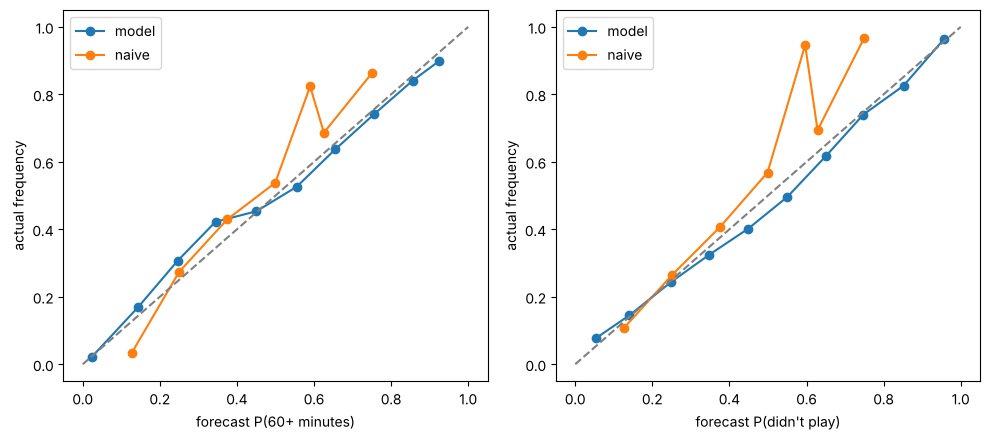

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (col, k, label) in zip(axes, [("p_60", 2, "P(60+ minutes)"), ("p_0", 0, "P(didn't play)")]):
    bins = pd.cut(bt[col], np.linspace(0, 1, 11))
    for prefix, name in (("", "model"), ("naive_", "naive")):
        g = bt.groupby(pd.cut(bt[prefix + col], np.linspace(0, 1, 11)), observed=True)
        cal = g.apply(lambda d: pd.Series({"pred": d[prefix + col].mean(), "actual": (d["bucket"] == k).mean()}))
        ax.plot(cal["pred"], cal["actual"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], ls="--", c="grey")
    ax.set_xlabel(f"forecast {label}")
    ax.set_ylabel("actual frequency")
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Expected points: hurdle vs. the baseline ridge

Both models see the same features, so any gap comes from the **structure**: modelling minutes first, then points.

In [3]:
results = pd.read_csv("../data/backtest_results_hurdle.csv")
compare(results, "hurdle", "ridge").round(3)

,hurdle,ridge,diff,t_stat,hurdle_wins
mae,1.027,1.065,-0.038,-17.718,1.000
rmse,1.964,1.967,-0.003,-1.112,0.571
ic,0.703,0.698,0.004,3.772,0.714
ic_starters,0.301,0.307,-0.006,-0.772,0.543
top20_pts,4.763,4.680,0.083,0.840,0.543


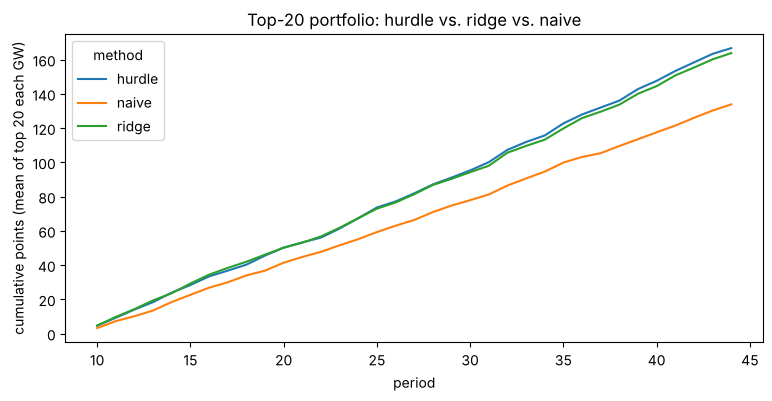

In [4]:
wide = results.pivot(index="period", columns="method", values="top20_pts")
ax = wide.cumsum().plot(figsize=(9, 4))
ax.set_ylabel("cumulative points (mean of top 20 each GW)")
ax.set_title("Top-20 portfolio: hurdle vs. ridge vs. naive")
plt.show()

As point forecasts the two models are close. The hurdle model has clearly lower average error (MAE) and slightly better overall IC. It ties on ranking starters and on the top-20 portfolio (the gap there is not significant).
Its real value is what the ridge model can't provide:

1. **Injury and suspension flags plug straight in.** FPL's "chance of playing" caps P(plays). The backtest can't use the flags because FPL keeps no history of them, so this edge isn't in the numbers above.
2. **A distribution, not just a mean.** The Layer 3 Monte Carlo simulator has to draw *did he play?* before *what did he score?*

## 3. Injury flags in the upcoming forecast

The ridge model knows nothing about injuries. For example, it still forecasts points for players who are ruled out.

In [5]:
fc = pd.read_csv("../data/forecast_next_gw_minutes.csv")
fc[fc["chance_pct"] < 100].sort_values("xpts_ridge", ascending=False)[
    ["web_name", "position", "price_m", "chance_pct", "news", "p_0", "p_60", "xpts", "xpts_ridge"]
].head(12).round(2)

,web_name,position,price_m,chance_pct,news,p_0,p_60,xpts,xpts_ridge
512,Saka,MID,9.6,0.0,Thigh injury - Unknown return date,1.00,0.00,0.00,4.81
206,Calvert-Lewin,FWD,6.1,50.0,Foot injury - 50% chance of playing,0.53,0.43,1.86,3.95
212,Stach,MID,6.0,50.0,Foot injury - 50% chance of playing,0.53,0.42,1.79,3.58
584,Janelt,MID,5.0,0.0,Suspended until 31 Oct,1.00,0.00,0.00,3.37
179,Manzambi,MID,6.0,75.0,Calf injury - 75% chance of playing,0.28,0.58,2.36,3.34
162,Matheus N.,DEF,5.9,75.0,Unspecified injury - 75% chance of playing,0.32,0.63,2.54,3.13
507,Martinez,GKP,5.0,0.0,Head injury - Unknown return date,1.00,0.00,0.00,3.06
309,Munoz,MID,6.5,25.0,Knee injury - 25% chance of playing,0.77,0.18,0.76,2.97
167,O'Reilly,DEF,6.3,75.0,Back injury - 75% chance of playing,0.32,0.50,2.50,2.91
233,Okafor,MID,5.8,50.0,Thigh injury - 50% chance of playing,0.56,0.37,1.45,2.91


## 4. Same expected points, different risk

Two players with similar xpts can be very different assets. One is nailed on with a modest return. The other is a rotation risk who scores well when he does play, so his outcomes are 0 or a lot.
This shows why the Layer 3 mean-variance optimizer needs the minutes model.

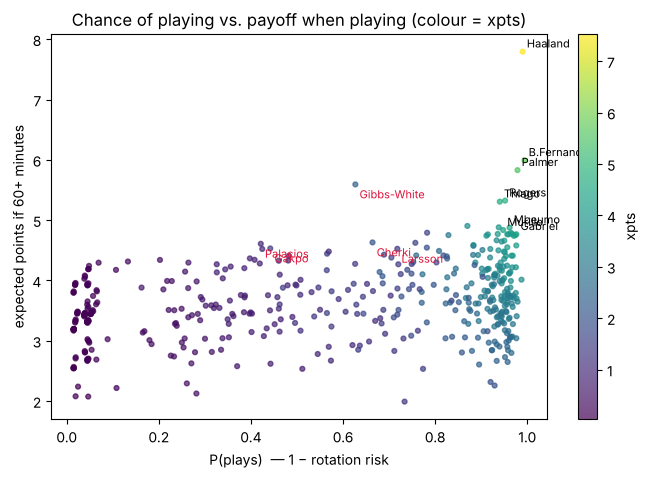

In [6]:
fc["p_play"] = 1 - fc["p_0"]
starters = fc[(fc["chance_pct"].isna()) | (fc["chance_pct"] == 100)]
ax = starters.plot.scatter("p_play", "pts_if_60", c="xpts", cmap="viridis", figsize=(8, 5), s=12, alpha=0.7)
for _, r in starters.nlargest(8, "xpts").iterrows():
    ax.annotate(r["web_name"], (r["p_play"], r["pts_if_60"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
risky = starters[(starters["p_play"].between(0.3, 0.75)) & (starters["pts_if_60"] > 4)].nlargest(5, "pts_if_60")
for _, r in risky.iterrows():
    ax.annotate(r["web_name"], (r["p_play"], r["pts_if_60"]), fontsize=8, color="crimson", xytext=(3, -10), textcoords="offset points")
ax.set_xlabel("P(plays)  — 1 − rotation risk")
ax.set_ylabel("expected points if 60+ minutes")
ax.set_title("Chance of playing vs. payoff when playing (colour = xpts)")
plt.show()

## Caveats and next steps

- Logistic regression is the simplest version of the README's "Bayesian / survival" minutes model. A hierarchical Bayesian version would share information across a team's squad, for example after a new manager arrives or fixtures congest.
- A double gameweek is bucketed by average minutes per fixture, which is a simplification.
- **Next: Layer 3.** Use these probabilities and conditional points to simulate whole gameweeks and seasons (Monte Carlo), then build a mean-variance squad optimizer on top.